# College Football Upset Vulnerability — Notebook 05: FBS-Only and Opponent-Strength Experiments



## 0. Load the saved data and split manifest



In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'

paths = {
    'team_games': PROCESSED / 'team_games.csv',
    'matchups': PROCESSED / 'matchup_features_initial.csv',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'features': PROCESSED / 'initial_feature_columns.json',
    'splits': PROCESSED / 'split_manifest.json',
}
for label, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'{label}: {path}. Run the earlier notebook export.')

team_games = pd.read_csv(paths['team_games'], parse_dates=['date'], low_memory=False)
matchups = pd.read_csv(paths['matchups'], parse_dates=['date'], low_memory=False)
eligibility = pd.read_csv(paths['eligibility'], low_memory=False)
feature_manifest = json.loads(paths['features'].read_text(encoding='utf-8'))
split_manifest = json.loads(paths['splits'].read_text(encoding='utf-8'))
folds = split_manifest['validation_folds']
test_seasons = set(map(int, split_manifest['test_seasons']))
assert test_seasons == {2024, 2025}
assert len(folds) == 5
assert matchups['game_id'].is_unique and eligibility['game_id'].is_unique
assert len(team_games) == 2 * len(matchups)
print('Team-games:', f'{len(team_games):,}', '| Matchups:', f'{len(matchups):,}')
print('Splits:', [(f['fold'], f['validation_season']) for f in folds])
print('Final-test seasons reserved:', sorted(test_seasons))

Mounted at /content/drive
Team-games: 36,600 | Matchups: 18,300
Splits: [('val_2019', 2019), ('val_2020', 2020), ('val_2021', 2021), ('val_2022', 2022), ('val_2023', 2023)]
Final-test seasons reserved: [2024, 2025]


## 1. Attach historical FBS/FCS membership to team-game records


In [ ]:
elig_cols = ['game_id','season','home','away','home_subdivision','away_subdivision','game_category','primary_fbs_fbs','partition']
missing = set(elig_cols) - set(eligibility.columns)
assert not missing, f'Missing eligibility columns: {missing}'

joined = team_games.merge(
    eligibility[elig_cols], on=['game_id','season'], how='left', validate='many_to_one'
)
assert len(joined) == len(team_games)

# Normalize bool loaded from CSV.
flag = joined['designated_home'].astype('string').str.strip().str.lower()
assert flag.isin(['true','false','1','0']).all(), 'Unexpected home designation'
joined['designated_home'] = flag.isin(['true','1'])

expected_team = np.where(joined['designated_home'], joined['home'], joined['away'])
expected_opp = np.where(joined['designated_home'], joined['away'], joined['home'])
assert (joined['team'].to_numpy() == expected_team).all(), 'Team name mismatch'
assert (joined['opponent'].to_numpy() == expected_opp).all(), 'Opponent mismatch'

joined['team_subdivision'] = np.where(
    joined['designated_home'], joined['home_subdivision'], joined['away_subdivision']
)
joined['opponent_subdivision'] = np.where(
    joined['designated_home'], joined['away_subdivision'], joined['home_subdivision']
)
joined['opponent_is_fbs'] = joined['opponent_subdivision'].eq('fbs')
assert joined.groupby('game_id').size().eq(2).all()
assert not joined.duplicated(['team','date']).any(), 'Same-day repeat: revise lag construction'

print('Recorded team-games by opponent division:')
display(joined['opponent_subdivision'].value_counts(dropna=False).to_frame('team_games'))
print('Unclassified games retained in history:',
      eligibility['game_category'].eq('unknown_membership').sum())

Recorded team-games by opponent division:


,team_games
opponent_subdivision,
fbs,34469
fcs,2105
unknown,25
d2,1


Unclassified games retained in history: 25


## 2. Compute FBS-only historical performance without looking ahead



In [ ]:
tg = joined.sort_values(['team','season','date','game_id'], kind='stable').copy()
group_keys = ['team','season']
grouped = tg.groupby(group_keys, sort=False)

# Build per-game contributions. Invalid/missing yards are not treated as zero observations.
tg['_fbs_game'] = tg['opponent_is_fbs'].astype(int)
tg['_fbs_win'] = tg['win'] * tg['_fbs_game']
tg['_fbs_margin'] = tg['margin'] * tg['_fbs_game']
tg['_fbs_yards_valid'] = (tg['opponent_is_fbs'] & tg['total_yards_for'].notna()).astype(int)
tg['_fbs_yards'] = tg['total_yards_for'].where(tg['_fbs_yards_valid'].eq(1), 0)

for new, source in [
    ('fbs_prior_games', '_fbs_game'),
    ('fbs_prior_wins', '_fbs_win'),
    ('_fbs_prior_margin_sum', '_fbs_margin'),
    ('fbs_prior_yardage_observations', '_fbs_yards_valid'),
    ('_fbs_prior_yardage_sum', '_fbs_yards'),
]:
    tg[new] = tg.groupby(group_keys, sort=False)[source].cumsum() - tg[source]

n = tg['fbs_prior_games'].replace(0, np.nan)
tg['fbs_prior_win_pct'] = tg['fbs_prior_wins'] / n
tg['fbs_prior_avg_margin'] = tg['_fbs_prior_margin_sum'] / n
tg['fbs_prior_avg_yards'] = (
    tg['_fbs_prior_yardage_sum'] /
    tg['fbs_prior_yardage_observations'].replace(0, np.nan)
)

assert (tg['fbs_prior_games'] <= tg['season_prior_games']).all()
assert tg.loc[tg.fbs_prior_games.eq(0),
              ['fbs_prior_win_pct','fbs_prior_avg_margin']].isna().all().all()
print('FBS-only histories created; first-game values remain undefined.')
preview = tg.loc[(tg['team']=='Kansas State') & (tg['season']==2025),
    ['date','team','opponent','opponent_subdivision','season_prior_games',
     'fbs_prior_games','season_prior_avg_margin','fbs_prior_avg_margin']]
display(preview.head(10))

FBS-only histories created; first-game values remain undefined.


,date,team,opponent,opponent_subdivision,season_prior_games,fbs_prior_games,season_prior_avg_margin,fbs_prior_avg_margin
13001,2025-08-23,Kansas State,Iowa State,fbs,0,0,NaN,NaN
13002,2025-08-30,Kansas State,North Dakota,fcs,1,1,-3.000000,-3.000000
13003,2025-09-06,Kansas State,Army,fbs,2,1,0.000000,-3.000000
13004,2025-09-12,Kansas State,Arizona,fbs,3,2,-1.000000,-3.000000
13005,2025-09-27,Kansas State,UCF,fbs,4,3,-2.250000,-4.000000
13006,2025-10-04,Kansas State,Baylor,fbs,5,4,1.000000,0.500000
13007,2025-10-11,Kansas State,TCU,fbs,6,5,0.666667,0.200000
13008,2025-10-25,Kansas State,Kansas,fbs,7,6,2.428571,2.333333
13009,2025-11-01,Kansas State,Texas Tech,fbs,8,7,5.250000,5.571429
13010,2025-11-15,Kansas State,Oklahoma State,fbs,9,8,2.111111,2.000000


## 3. Construct a strictly pregame opponent-strength proxy



In [ ]:
# Reverse-lookup from the other team's strictly pregame snapshot.
other_snapshot = tg[['game_id','team','fbs_prior_avg_margin']].rename(
    columns={'team':'opponent','fbs_prior_avg_margin':'opponent_fbs_margin_at_kickoff'}
)
tg = tg.merge(other_snapshot, on=['game_id','opponent'], how='left', validate='one_to_one')
assert len(tg) == len(joined)
tg['opponent_fbs_margin_at_kickoff'] = tg['opponent_fbs_margin_at_kickoff'].where(
    tg['opponent_is_fbs']
)

# Only observations against FBS teams with a pregame FBS-strength estimate.
tg['_known_opp_rating'] = tg['opponent_fbs_margin_at_kickoff'].notna().astype(int)
tg['_opp_rating_contribution'] = tg['opponent_fbs_margin_at_kickoff'].fillna(0)
for new, source in [
    ('sos_prior_known_games','_known_opp_rating'),
    ('_sos_prior_strength_sum','_opp_rating_contribution'),
]:
    tg[new] = tg.groupby(group_keys, sort=False)[source].cumsum() - tg[source]
tg['sos_prior_avg_opponent_margin'] = (
    tg['_sos_prior_strength_sum'] / tg['sos_prior_known_games'].replace(0,np.nan)
)
tg['sos_prior_coverage'] = (
    tg['sos_prior_known_games'] / tg['fbs_prior_games'].replace(0,np.nan)
)
tg['fbs_prior_strength_adjusted_margin'] = (
    tg['fbs_prior_avg_margin'] + tg['sos_prior_avg_opponent_margin']
)
assert (tg['sos_prior_known_games'] <= tg['fbs_prior_games']).all()
assert tg['sos_prior_coverage'].dropna().between(0,1).all()
print('SOS feature coverage on team-games:',
      f"{tg['sos_prior_avg_opponent_margin'].notna().mean():.1%}")
display(tg.loc[(tg.team=='Kansas State') & (tg.season==2025),
    ['date','opponent','fbs_prior_games','fbs_prior_avg_margin',
     'sos_prior_known_games','sos_prior_avg_opponent_margin',
     'fbs_prior_strength_adjusted_margin']].head(10))

SOS feature coverage on team-games: 75.7%


,date,opponent,fbs_prior_games,fbs_prior_avg_margin,sos_prior_known_games,sos_prior_avg_opponent_margin,fbs_prior_strength_adjusted_margin
13001,2025-08-23,Iowa State,0,NaN,0,NaN,NaN
13002,2025-08-30,North Dakota,1,-3.000000,0,NaN,NaN
13003,2025-09-06,Army,1,-3.000000,0,NaN,NaN
13004,2025-09-12,Arizona,2,-3.000000,0,NaN,NaN
13005,2025-09-27,UCF,3,-4.000000,1,34.000000,30.000000
13006,2025-10-04,Baylor,4,0.500000,2,25.000000,25.500000
13007,2025-10-11,TCU,5,0.200000,3,17.000000,17.200000
13008,2025-10-25,Kansas,6,2.333333,4,16.250000,18.583333
13009,2025-11-01,Texas Tech,7,5.571429,5,13.766667,19.338095
13010,2025-11-15,Oklahoma State,8,2.000000,6,15.996032,17.996032


## 4. Audit the historical calculation directly



In [ ]:
sample_pool = tg.loc[tg['season_prior_games'].gt(0)]
sample = sample_pool.sample(n=min(80,len(sample_pool)),random_state=42)
for row in sample.itertuples(index=False):
    prior = tg.loc[(tg.team==row.team) & (tg.season==row.season) & (tg.date < row.date)]
    prior_fbs = prior.loc[prior.opponent_is_fbs]
    assert len(prior_fbs) == row.fbs_prior_games
    assert prior_fbs.win.sum() == row.fbs_prior_wins
    expected_margin = prior_fbs.margin.mean()
    assert np.isclose(expected_margin,row.fbs_prior_avg_margin,equal_nan=True)
    expected_sos = prior['opponent_fbs_margin_at_kickoff'].mean()
    assert np.isclose(expected_sos,row.sos_prior_avg_opponent_margin,equal_nan=True)
    assert prior['opponent_fbs_margin_at_kickoff'].notna().sum() == row.sos_prior_known_games

# Critical: all first-season games have no current-season FBS information.
first = tg['season_prior_games'].eq(0)
assert tg.loc[first,'fbs_prior_games'].eq(0).all()
assert tg.loc[first,'sos_prior_known_games'].eq(0).all()
assert tg.loc[first,'sos_prior_avg_opponent_margin'].isna().all()

print(f'Checks passed: {len(sample)} historical team-game rows and {first.sum():,} first-season games.')

Checks passed: 80 historical team-game rows and 4,444 first-season games.


## 5. Reassemble matchup features and specify experimental groups



In [ ]:
FBS_SIDE = ['fbs_prior_games','fbs_prior_wins','fbs_prior_win_pct',
            'fbs_prior_avg_margin','fbs_prior_avg_yards','fbs_prior_yardage_observations']
SOS_SIDE = ['sos_prior_known_games','sos_prior_coverage',
            'sos_prior_avg_opponent_margin','fbs_prior_strength_adjusted_margin']
DIFF_FEATURES = ['fbs_prior_win_pct','fbs_prior_avg_margin','fbs_prior_avg_yards',
                 'sos_prior_coverage','sos_prior_avg_opponent_margin',
                 'fbs_prior_strength_adjusted_margin']

def side_table(side):
    side_is_home = side=='home'
    cols = ['game_id','team',*FBS_SIDE,*SOS_SIDE]
    out = tg.loc[tg.designated_home.eq(side_is_home),cols].copy()
    out = out.rename(columns={'team':side,**{c:f'{side}_{c}' for c in FBS_SIDE+SOS_SIDE}})
    return out

augmented = matchups.merge(side_table('home'),on=['game_id','home'],how='left',validate='one_to_one')
augmented = augmented.merge(side_table('away'),on=['game_id','away'],how='left',validate='one_to_one')
assert len(augmented)==len(matchups)
assert augmented['game_id'].is_unique
for f in DIFF_FEATURES:
    augmented[f'diff_{f}'] = augmented[f'home_{f}']-augmented[f'away_{f}']

initial = list(feature_manifest['feature_columns'])
assert len(initial)==19 and len(set(initial))==19
fbs_add = [f'{s}_{f}' for s in ('home','away') for f in FBS_SIDE] + [f'diff_{f}' for f in DIFF_FEATURES[:3]]
sos_add = [f'{s}_{f}' for s in ('home','away') for f in SOS_SIDE] + [f'diff_{f}' for f in DIFF_FEATURES[3:]]
FEATURE_SETS = {
    'initial_19': initial,
    'plus_fbs_history': initial + fbs_add,
    'plus_fbs_and_sos': initial + fbs_add + sos_add,
}
assert all(len(v)==len(set(v)) for v in FEATURE_SETS.values())
assert all(set(v).issubset(augmented.columns) for v in FEATURE_SETS.values())
assert all(not set(v)&{'home_win','home_margin','score_home','score_away','margin','win'}
           for v in FEATURE_SETS.values())
print('Candidate sets:')
for name,cols in FEATURE_SETS.items(): print(' -',name,len(cols),'features')
print('New-feature missingness (all dates, descriptive only):')
display(augmented[fbs_add+sos_add].isna().mean().mul(100)
        .sort_values(ascending=False).rename('missing_pct').head(15).to_frame().round(1))

Candidate sets:
 - initial_19 19 features
 - plus_fbs_history 34 features
 - plus_fbs_and_sos 45 features
New-feature missingness (all dates, descriptive only):


,missing_pct
diff_sos_prior_avg_opponent_margin,28.0
diff_fbs_prior_strength_adjusted_margin,28.0
away_sos_prior_avg_opponent_margin,25.7
away_fbs_prior_strength_adjusted_margin,25.7
home_fbs_prior_strength_adjusted_margin,22.9
home_sos_prior_avg_opponent_margin,22.9
diff_fbs_prior_avg_yards,18.5
diff_fbs_prior_avg_margin,18.4
diff_sos_prior_coverage,18.4
diff_fbs_prior_win_pct,18.4


## 6. Compare the same Logistic Regression pipeline on 2019–2023 folds



In [ ]:
elig_features = eligibility[['game_id','season','home','away','primary_fbs_fbs','partition']]
modeling = augmented.merge(elig_features,on=['game_id','season','home','away'],
                           how='left',validate='one_to_one')
assert modeling['primary_fbs_fbs'].notna().all()
modeling = modeling.loc[modeling.primary_fbs_fbs.astype(str).str.lower().isin(['true','1'])].copy()
modeling = modeling.loc[~modeling['season'].isin(test_seasons)].copy()
assert modeling['season'].max()<=2023
expected_model_rows = eligibility.loc[eligibility.season.le(2023), 'primary_fbs_fbs'].astype(str).str.lower().isin(['true','1']).sum()
assert len(modeling)==expected_model_rows, 'Unexpected FBS–FBS count through 2023'

for col in set(sum(FEATURE_SETS.values(),[])):
    if col == 'neutral':
        modeling[col] = modeling[col].astype('string').str.lower().map(
            {'true':1.0,'false':0.0,'1':1.0,'0':0.0})
        assert modeling[col].notna().all()
    else:
        before = modeling[col].isna().sum()
        modeling[col] = pd.to_numeric(modeling[col],errors='coerce')
        assert modeling[col].isna().sum()==before, f'Unexpected nonnumeric {col}'

def model_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42))
    ])

def evaluate(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    return {'n_games':len(y),'accuracy':accuracy_score(y,p>=.5),
            'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if len(set(y))==2 else np.nan}

fold_rows=[]; predictions=[]
for fold in folds:
    start,end=map(int,fold['train_seasons']);year=int(fold['validation_season'])
    assert start==2004 and end==year-1
    tr=modeling.loc[modeling.season.between(start,end)]
    va=modeling.loc[modeling.season.eq(year)]
    assert tr.season.max()<va.season.min()
    assert set(tr.game_id).isdisjoint(set(va.game_id))
    for model_name,cols in FEATURE_SETS.items():
        m=model_pipeline()
        m.fit(tr[cols],tr['home_win'].astype(int))
        p=m.predict_proba(va[cols])[:,list(m.named_steps['classifier'].classes_).index(1)]
        fold_rows.append({'fold':fold['fold'],'validation_season':year,'model':model_name,
                          'n_train':len(tr),**evaluate(va['home_win'],p)})
        results=va[['game_id','season','date','home','away','home_win']].copy()
        results['model']=model_name
        results['predicted_p_home_win']=p
        predictions.append(results)
    print(f"Validated {year}: {len(tr):,} train / {len(va):,} validation games")

fold_scores=pd.DataFrame(fold_rows)
oof=pd.concat(predictions,ignore_index=True)
assert not oof.season.isin(test_seasons).any()
assert oof.groupby(['model','game_id']).size().eq(1).all()
print('Per-fold results:')
display(fold_scores[['fold','model','n_games','accuracy','brier','log_loss','roc_auc']].round(4))

Validated 2019: 10,917 train / 774 validation games
Validated 2020: 11,691 train / 534 validation games
Validated 2021: 12,225 train / 770 validation games
Validated 2022: 12,995 train / 776 validation games
Validated 2023: 13,771 train / 792 validation games
Per-fold results:


,fold,model,n_games,accuracy,brier,log_loss,roc_auc
0,val_2019,initial_19,774,0.7054,0.1911,0.5636,0.7665
1,val_2019,plus_fbs_history,774,0.7132,0.1893,0.5582,0.7701
2,val_2019,plus_fbs_and_sos,774,0.7209,0.1875,0.5541,0.7735
3,val_2020,initial_19,534,0.6816,0.2083,0.6023,0.7276
4,val_2020,plus_fbs_history,534,0.6948,0.2056,0.5960,0.7363
5,val_2020,plus_fbs_and_sos,534,0.6910,0.2040,0.5932,0.7443
6,val_2021,initial_19,770,0.6805,0.2024,0.5888,0.7380
7,val_2021,plus_fbs_history,770,0.6935,0.1993,0.5830,0.7476
8,val_2021,plus_fbs_and_sos,770,0.7000,0.1984,0.5801,0.7516
9,val_2022,initial_19,776,0.6830,0.2058,0.6008,0.7278


## 7. Aggregate results and check whether extra features genuinely helped


Pooled out-of-fold metrics (3,646 validation games per model):


,model,n_games,accuracy,brier,log_loss,roc_auc,brier_change_from_initial
1,plus_fbs_and_sos,3646,0.70159,0.19649,0.57607,0.75413,-0.00365
2,plus_fbs_history,3646,0.70022,0.19760,0.57876,0.75084,-0.00254
0,initial_19,3646,0.69144,0.20014,0.58496,0.74406,0.00000


Notebook 04 baseline Brier difference: 0.00000000


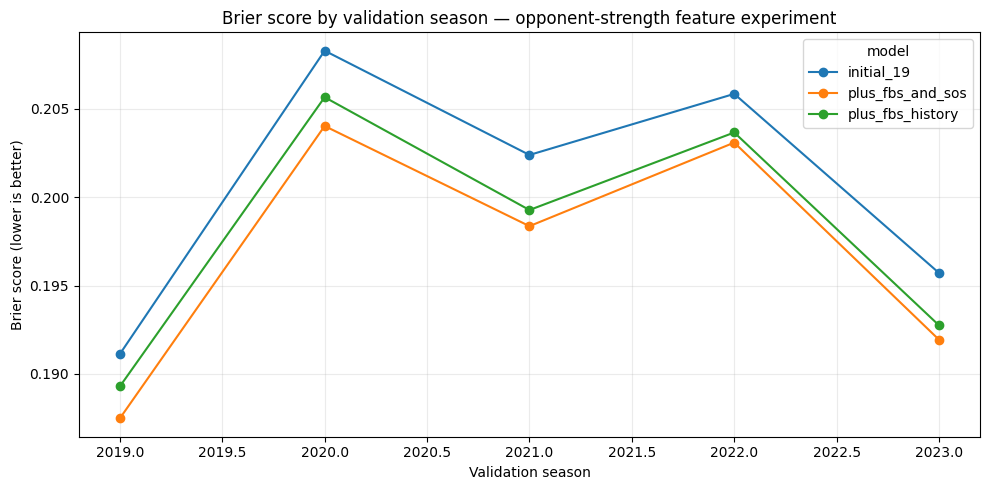

Per-season Brier differences relative to initial_19 (negative = improvement):


model,initial_19,plus_fbs_and_sos,plus_fbs_history
validation_season,,,
2019,0.0,-0.0036,-0.0018
2020,0.0,-0.0043,-0.0026
2021,0.0,-0.0040,-0.0031
2022,0.0,-0.0028,-0.0022
2023,0.0,-0.0038,-0.0030


In [ ]:
pooled=[]
for name,df in oof.groupby('model'):
    pooled.append({'model':name,**evaluate(df.home_win,df.predicted_p_home_win)})
pooled=pd.DataFrame(pooled).sort_values('brier')
base=pooled.loc[pooled.model.eq('initial_19'),'brier'].iloc[0]
pooled['brier_change_from_initial'] = pooled['brier'] - base
print('Pooled out-of-fold metrics (3,646 validation games per model):')
display(pooled.round(5))

base_file = OUTPUT_DIR/'baseline_pooled_scores.csv'
if base_file.is_file():
    previous=pd.read_csv(base_file)
    expected=previous.loc[previous.model.eq('initial_19'),'brier']
    if len(expected)==1:
        diff=abs(float(expected.iloc[0])-float(base))
        print(f'Notebook 04 baseline Brier difference: {diff:.8f}')
        if diff>1e-7:
            print('WARNING: Baseline does not reproduce exactly. Check input versions before interpreting new features.')

brier_pivot=fold_scores.pivot(index='validation_season',columns='model',values='brier')
ax=brier_pivot.plot(marker='o',figsize=(10,5))
ax.set(title='Brier score by validation season — opponent-strength feature experiment',
       xlabel='Validation season',ylabel='Brier score (lower is better)')
ax.grid(alpha=0.25)
plt.tight_layout();plt.show()

print('Per-season Brier differences relative to initial_19 (negative = improvement):')
delta=brier_pivot.subtract(brier_pivot['initial_19'],axis=0)
display(delta.round(4))

## 8. Save reproducible experiment artifacts to Google Drive


In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
feature_file=PROCESSED/'matchup_features_opponent_strength.csv'
manifest_file=PROCESSED/'opponent_strength_feature_manifest.json'
fold_file=OUTPUT_DIR/'opponent_strength_fold_scores.csv'
pooled_file=OUTPUT_DIR/'opponent_strength_pooled_scores.csv'
oof_file=OUTPUT_DIR/'opponent_strength_oof_predictions_2019_2023.csv'

augmented.to_csv(feature_file,index=False)
manifest={
    'purpose':'FBS-only history and historical opponent pregame strength experiment',
    'candidate_feature_groups':FEATURE_SETS,
    'target':'home_win',
    'validation_folds':folds,
    'reserved_final_test_seasons':sorted(test_seasons),
    'sos_definition':'Mean of earlier FBS opponents pregame FBS-only average margin at time of game; require known observations',
    'note':'End-of-season opponent statistics and actual current-game results are never used as current-game inputs.',
}
manifest_file.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
fold_scores.to_csv(fold_file,index=False)
pooled.to_csv(pooled_file,index=False)
oof.to_csv(oof_file,index=False)
print('Saved:')
for path in [feature_file,manifest_file,fold_file,pooled_file,oof_file]: print(' -',path)
print('2024–2025 prediction/evaluation remain untouched.')

Saved:
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_opponent_strength.csv
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/opponent_strength_feature_manifest.json
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/opponent_strength_fold_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/opponent_strength_pooled_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/opponent_strength_oof_predictions_2019_2023.csv
2024–2025 prediction/evaluation remain untouched.
